In [2]:
import sys

print(sys.executable)

D:\anaconda3\envs\plantcare\python.exe


In [3]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())

PyTorch version: 2.9.1+cu130
CUDA version: 13.0
CUDA available: True
GPU: NVIDIA GeForce GTX 1650
GPU count: 1


In [4]:
import torch

if torch.cuda.is_available():

    device = torch.device("cuda")

    x = torch.rand(5000, 5000, device=device)
    y = torch.rand(5000, 5000, device=device)

    z = torch.matmul(x, y)

    print("GPU test successful!")
    print("Device:", z.device)

else:
    print("CUDA is not available.")

GPU test successful!
Device: cuda:0


In [5]:
BATCH_SIZE = 16

In [6]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.9.1+cu130
CUDA: 13.0
CUDA available: True
GPU: NVIDIA GeForce GTX 1650


In [7]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("CUDA is NOT available")

PyTorch: 2.9.1+cu130
CUDA: 13.0
CUDA available: True
GPU: NVIDIA GeForce GTX 1650
GPU Memory: 4.0 GB


In [8]:
import sys

!{sys.executable} -m pip install pandas numpy matplotlib scikit-learn pillow tqdm

In [9]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tqdm.notebook import tqdm

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [10]:
DATASET_DIR = r"D:\SEM-9\Project\agri_foundation_v1\agri_foundation_v1\data"

In [11]:
print("Dataset path:")
print(DATASET_DIR)

print("\nExists:", os.path.exists(DATASET_DIR))

Dataset path:
D:\SEM-9\Project\agri_foundation_v1\agri_foundation_v1\data

Exists: True


In [12]:
classes = sorted([
    folder
    for folder in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, folder))
])

print("Number of classes:", len(classes))

for i, class_name in enumerate(classes):
    print(f"{i}: {class_name}")

Number of classes: 215
0: apple_black_rot
1: apple_cedar_rust
2: apple_healthy
3: apple_mosaic_virus
4: apple_rust
5: apple_scab
6: banana
7: banana_banana_anthracnose
8: banana_banana_black_streak
9: banana_banana_black_streak_banana_black_sigatoka_()
10: banana_banana_bunchy_top
11: banana_banana_cigar_end_rot
12: banana_banana_cordana_spot
13: banana_banana_panama_disease
14: banana_panama_disease
15: basil
16: basil_basil_downy_mildew
17: basil_downy_mildew
18: bean
19: bean_bean_halo_blight
20: bean_bean_mosaic_virus
21: bean_bean_rust
22: bean_halo_blight
23: bean_mosaic_virus
24: bean_rust
25: blueberry_anthracnose
26: blueberry_botrytis_blight
27: blueberry_healthy
28: blueberry_mummy_berry
29: blueberry_rust
30: blueberry_scorch
31: broccoli
32: broccoli_broccoli_alternaria_spot
33: broccoli_broccoli_downy_mildew
34: broccoli_broccoli_ring_spot
35: broccoli_downy_mildew
36: cabbage
37: cabbage_alternaria_spot
38: cabbage_cabbage_alternaria_spot
39: cabbage_cabbage_black_rot
40

In [13]:
VALID_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

class_counts = {}

for class_name in classes:

    class_path = os.path.join(DATASET_DIR, class_name)

    count = 0

    for filename in os.listdir(class_path):

        if filename.lower().endswith(VALID_EXTENSIONS):
            count += 1

    class_counts[class_name] = count


count_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Plant", "Images"]
)

count_df = count_df.sort_values(
    "Images",
    ascending=True
)

display(count_df)

,Plant,Images
40,cabbage_cabbage_black_rot_bing_-_copy,1
45,carrot_cavity_spot,2
190,tomato_two_spotted_spider_mites,2
71,coffee_coffee_black_rot,6
129,peach_rust_bing,8
...,...,...
5,apple_scab,2897
2,apple_healthy,3034
182,tomato_healthy,3430
191,tomato_yellow_curl_virus,5348


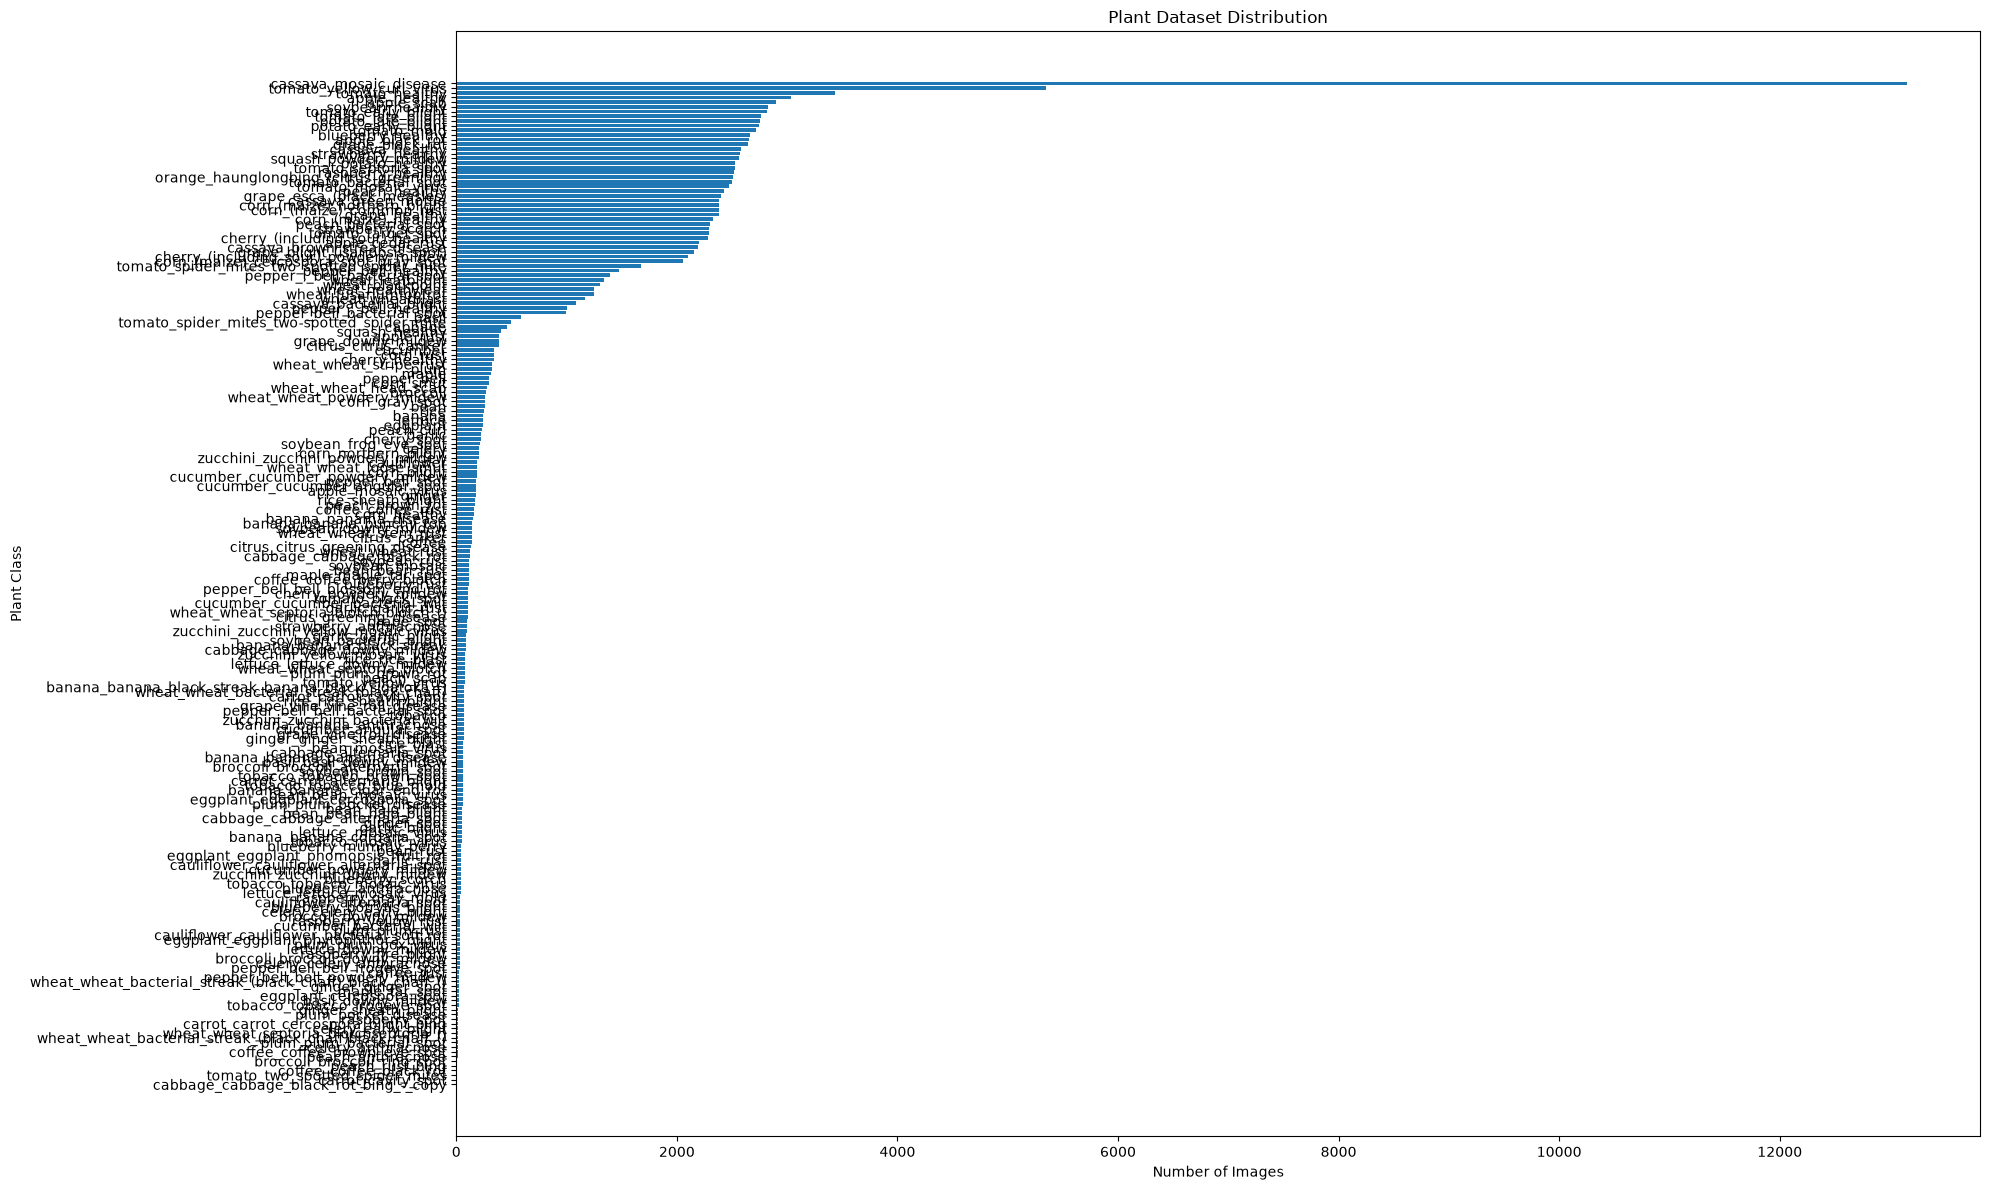

In [14]:
plt.figure(figsize=(20, 12))

plt.barh(
    count_df["Plant"],
    count_df["Images"]
)

plt.xlabel("Number of Images")
plt.ylabel("Plant Class")
plt.title("Plant Dataset Distribution")

plt.tight_layout()
plt.show()

In [7]:
MIN_IMAGES = 2

valid_classes = [
    class_name
    for class_name, count in class_counts.items()
    if count >= MIN_IMAGES
]

ignored_classes = [
    class_name
    for class_name, count in class_counts.items()
    if count < MIN_IMAGES
]

print("Valid classes:", len(valid_classes))

print("\nIgnored classes:")
for class_name in ignored_classes:
    print(class_name, "->", class_counts[class_name], "image(s)")

Valid classes: 214

Ignored classes:
cabbage_cabbage_black_rot_bing_-_copy -> 1 image(s)


In [8]:
image_paths = []
image_labels = []

class_to_index = {
    class_name: index
    for index, class_name in enumerate(valid_classes)
}

for class_name in valid_classes:

    class_path = os.path.join(
        DATASET_DIR,
        class_name
    )

    label = class_to_index[class_name]

    for filename in os.listdir(class_path):

        if filename.lower().endswith(VALID_EXTENSIONS):

            image_path = os.path.join(
                class_path,
                filename
            )

            image_paths.append(image_path)
            image_labels.append(label)

print("Total valid images:", len(image_paths))
print("Total classes:", len(valid_classes))

Total valid images: 144750
Total classes: 214


In [9]:
label_counts = Counter(image_labels)

for label, count in sorted(label_counts.items()):

    print(
        f"{valid_classes[label]}: {count} images"
    )

apple_black_rot: 2654 images
apple_cedar_rust: 2200 images
apple_healthy: 3034 images
apple_mosaic_virus: 178 images
apple_rust: 391 images
apple_scab: 2897 images
banana: 243 images
banana_banana_anthracnose: 69 images
banana_banana_black_streak: 85 images
banana_banana_black_streak_banana_black_sigatoka_(): 74 images
banana_banana_bunchy_top: 142 images
banana_banana_cigar_end_rot: 57 images
banana_banana_cordana_spot: 51 images
banana_banana_panama_disease: 63 images
banana_panama_disease: 149 images
basil: 588 images
basil_basil_downy_mildew: 63 images
basil_downy_mildew: 23 images
bean: 257 images
bean_bean_halo_blight: 56 images
bean_bean_mosaic_virus: 57 images
bean_bean_rust: 114 images
bean_halo_blight: 56 images
bean_mosaic_virus: 64 images
bean_rust: 46 images
blueberry_anthracnose: 40 images
blueberry_botrytis_blight: 36 images
blueberry_healthy: 2662 images
blueberry_mummy_berry: 46 images
blueberry_rust: 112 images
blueberry_scorch: 42 images
broccoli: 269 images
broccoli

In [10]:
base_dataset = datasets.ImageFolder(
    DATASET_DIR
)

print("Original classes:", len(base_dataset.classes))

Original classes: 215


In [24]:
import shutil

FILTERED_DIR = r"D:\SEM-9\Project\PlantDataset_Filtered"

os.makedirs(FILTERED_DIR, exist_ok=True)

for class_name in valid_classes:

    source_dir = os.path.join(
        DATASET_DIR,
        class_name
    )

    destination_dir = os.path.join(
        FILTERED_DIR,
        class_name
    )

    os.makedirs(
        destination_dir,
        exist_ok=True
    )

    for filename in os.listdir(source_dir):

        if filename.lower().endswith(VALID_EXTENSIONS):

            source = os.path.join(
                source_dir,
                filename
            )

            destination = os.path.join(
                destination_dir,
                filename
            )

            if not os.path.exists(destination):

                shutil.copy2(
                    source,
                    destination
                )

print("Filtered dataset created.")
print(FILTERED_DIR)

Filtered dataset created.
D:\SEM-9\Project\PlantDataset_Filtered


In [25]:
weights = EfficientNet_B0_Weights.DEFAULT

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [26]:
train_dataset_full = datasets.ImageFolder(
    FILTERED_DIR,
    transform=train_transform
)

val_dataset_full = datasets.ImageFolder(
    FILTERED_DIR,
    transform=val_transform
)

class_names = train_dataset_full.classes

num_classes = len(class_names)

print("Number of classes:", num_classes)

print("\nClasses:")
for i, name in enumerate(class_names):
    print(i, "->", name)

Number of classes: 214

Classes:
0 -> apple_black_rot
1 -> apple_cedar_rust
2 -> apple_healthy
3 -> apple_mosaic_virus
4 -> apple_rust
5 -> apple_scab
6 -> banana
7 -> banana_banana_anthracnose
8 -> banana_banana_black_streak
9 -> banana_banana_black_streak_banana_black_sigatoka_()
10 -> banana_banana_bunchy_top
11 -> banana_banana_cigar_end_rot
12 -> banana_banana_cordana_spot
13 -> banana_banana_panama_disease
14 -> banana_panama_disease
15 -> basil
16 -> basil_basil_downy_mildew
17 -> basil_downy_mildew
18 -> bean
19 -> bean_bean_halo_blight
20 -> bean_bean_mosaic_virus
21 -> bean_bean_rust
22 -> bean_halo_blight
23 -> bean_mosaic_virus
24 -> bean_rust
25 -> blueberry_anthracnose
26 -> blueberry_botrytis_blight
27 -> blueberry_healthy
28 -> blueberry_mummy_berry
29 -> blueberry_rust
30 -> blueberry_scorch
31 -> broccoli
32 -> broccoli_broccoli_alternaria_spot
33 -> broccoli_broccoli_downy_mildew
34 -> broccoli_broccoli_ring_spot
35 -> broccoli_downy_mildew
36 -> cabbage
37 -> cabbag

In [27]:
all_indices = np.arange(
    len(train_dataset_full)
)

all_labels = np.array([
    label
    for _, label in train_dataset_full.samples
])

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))

Training images: 115800
Validation images: 28950


In [28]:
train_dataset = Subset(
    train_dataset_full,
    train_indices
)

val_dataset = Subset(
    val_dataset_full,
    val_indices
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

Train: 115800
Validation: 28950


In [29]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders ready.")

DataLoaders ready.


In [30]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

Device: cuda
GPU: NVIDIA GeForce GTX 1650
GPU memory: 4.0 GB


In [31]:
weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(
    weights=weights
)

In [32]:
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    num_classes
)

model = model.to(device)

print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=214, bias=True)
)


In [33]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

In [34]:
use_amp = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print("Mixed precision:", use_amp)

Mixed precision: True


In [ ]:
EPOCHS = 10

best_val_accuracy = 0.0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):

    # =========================
    # TRAIN
    # =========================

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for images, labels in progress_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        _, predictions = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predictions == labels
        ).sum().item()

        train_accuracy = (
            100 * correct / total
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            accuracy=f"{train_accuracy:.2f}%"
        )

    train_loss = (
        running_loss /
        len(train_loader)
    )

    train_accuracy = (
        100 * correct / total
    )

    # =========================
    # VALIDATION
    # =========================

    model.eval()

    val_loss_total = 0.0

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=use_amp
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

            val_loss_total += loss.item()

            _, predictions = torch.max(
                outputs,
                1
            )

            val_total += labels.size(0)

            val_correct += (
                predictions == labels
            ).sum().item()

    val_loss = (
        val_loss_total /
        len(val_loader)
    )

    val_accuracy = (
        100 * val_correct / val_total
    )

    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_accuracy
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_accuracy"].append(
        val_accuracy
    )

    scheduler.step(val_loss)

    print(
        f"\nEpoch {epoch + 1}/{EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: {train_accuracy:.2f}%"
    )

    print(
        f"Validation Loss: {val_loss:.4f}"
    )

    print(
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

    # =========================
    # SAVE BEST MODEL
    # =========================

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": class_names,
                "num_classes": num_classes
            },
            "plant_care_best.pth"
        )

        print(
            "✓ Best model saved!"
        )

    print("-" * 60)

Epoch 1/10:   0%|          | 0/7238 [00:00<?, ?it/s]

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "Plant Care Model Accuracy"
)

plt.legend()

plt.grid()

plt.show()

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Plant Care Model Loss"
)

plt.legend()

plt.grid()

plt.show()

In [ ]:
checkpoint = torch.load(
    "plant_care_best.pth",
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

class_names = checkpoint["class_names"]

model = model.to(device)

model.eval()

print("Best model loaded.")
print("Classes:", len(class_names))

In [ ]:
IMAGE_PATH = r"D:\SEM-9\Project\Image.2.jpeg"

In [ ]:
print(
    "Image exists:",
    os.path.exists(IMAGE_PATH)
)

In [ ]:
def predict_plant(
    image_path,
    model,
    class_names,
    device
):

    image = Image.open(
        image_path
    ).convert("RGB")

    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[
                0.485,
                0.456,
                0.406
            ],
            std=[
                0.229,
                0.224,
                0.225
            ]
        )
    ])

    image_tensor = transform(
        image
    ).unsqueeze(0)

    image_tensor = image_tensor.to(
        device
    )

    model.eval()

    with torch.no_grad():

        outputs = model(
            image_tensor
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        confidence, prediction = torch.max(
            probabilities,
            dim=1
        )

    predicted_class = class_names[
        prediction.item()
    ]

    confidence_value = (
        confidence.item() * 100
    )

    return (
        image,
        predicted_class,
        confidence_value
    )

In [ ]:
image, plant_name, confidence = predict_plant(
    IMAGE_PATH,
    model,
    class_names,
    device
)

print("Plant:", plant_name)
print(
    "Confidence:",
    f"{confidence:.2f}%"
)

In [ ]:
plt.figure(figsize=(7, 7))

plt.imshow(image)

plt.title(
    f"Plant: {plant_name}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")

plt.show()

In [ ]:
def predict_top5(
    image_path,
    model,
    class_names,
    device
):

    image = Image.open(
        image_path
    ).convert("RGB")

    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[
                0.485,
                0.456,
                0.406
            ],
            std=[
                0.229,
                0.224,
                0.225
            ]
        )
    ])

    image_tensor = transform(
        image
    ).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():

        output = model(
            image_tensor
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

        top_probabilities, top_indices = torch.topk(
            probabilities,
            min(5, len(class_names)),
            dim=1
        )

    print("\nTop Predictions")
    print("=" * 40)

    for probability, index in zip(
        top_probabilities[0],
        top_indices[0]
    ):

        print(
            f"{class_names[index.item()]:30s}"
            f"{probability.item()*100:.2f}%"
        )

In [ ]:
predict_top5(
    IMAGE_PATH,
    model,
    class_names,
    device
)

In [ ]:
with open(
    "plant_classes.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        class_names,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Class names saved.")